In [1]:
# ============================================================
# IMPORTS
# ============================================================

from pathlib import Path
import json
import random
import copy
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    median_absolute_error,
    r2_score
)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

print("Imports ok")

Imports ok


## Load Data from notebook 

In [2]:
# ============================================================
# NOTEBOOK CONFIGURATION
# ============================================================

SEED = 42

PROJECT_DIR = Path(
    r"C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility"
)

DATA_DIR = PROJECT_DIR / "processed_data_final"

OUTPUT_DIR = DATA_DIR / "transformer_baseline_runs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

BRAKE_THRESHOLD = -0.2
ACCEL_THRESHOLD = 0.2

HISTORY = 25
HORIZON = 1
STRIDE = 1

BATCH_SIZE = 128
NUM_EPOCHS = 15
LR = 1e-3

THRESHOLD_TAG = f"brake{abs(BRAKE_THRESHOLD):.1f}_accel{ACCEL_THRESHOLD:.1f}".replace(".", "p")
SEQUENCE_TAG = f"H{HISTORY}_Hz{HORIZON}_S{STRIDE}"

EXPERIMENT_NAME = f"transformer_baseline_{SEQUENCE_TAG}_{THRESHOLD_TAG}"

RUN_DIR = OUTPUT_DIR / EXPERIMENT_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)

print("Using regime definition:")
print(f"braking      : y_true < {BRAKE_THRESHOLD}")
print(f"accelerating : y_true > {ACCEL_THRESHOLD}")
print("steady       : otherwise")

print("Data dir:", DATA_DIR)
print("Run dir:", RUN_DIR)

Using regime definition:
braking      : y_true < -0.2
accelerating : y_true > 0.2
steady       : otherwise
Data dir: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final
Run dir: C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\transformer_baseline_runs\transformer_baseline_H25_Hz1_S1_brake0p2_accel0p2


In [3]:
# ============================================================
# LOAD PRE-SPLIT DATASETS
# ============================================================

required_files = [
    DATA_DIR / "episode_tracks_train.csv",
    DATA_DIR / "episode_tracks_val.csv",
    DATA_DIR / "episode_tracks_test.csv",
    DATA_DIR / "episodes_metadata_train.csv",
    DATA_DIR / "episodes_metadata_val.csv",
    DATA_DIR / "episodes_metadata_test.csv",
]

for p in required_files:
    assert p.exists(), f"Missing required file: {p}"

episode_tracks_train = pd.read_csv(DATA_DIR / "episode_tracks_train.csv")
episode_tracks_val   = pd.read_csv(DATA_DIR / "episode_tracks_val.csv")
episode_tracks_test  = pd.read_csv(DATA_DIR / "episode_tracks_test.csv")

episodes_train = pd.read_csv(DATA_DIR / "episodes_metadata_train.csv")
episodes_val   = pd.read_csv(DATA_DIR / "episodes_metadata_val.csv")
episodes_test  = pd.read_csv(DATA_DIR / "episodes_metadata_test.csv")

print("\n=== DATASET SIZES ===")
print("Train frame-level rows:", len(episode_tracks_train))
print("Val frame-level rows:  ", len(episode_tracks_val))
print("Test frame-level rows: ", len(episode_tracks_test))

print("\nTrain episodes:", len(episodes_train))
print("Val episodes:  ", len(episodes_val))
print("Test episodes: ", len(episodes_test))

print("\nTrain egos:", episode_tracks_train["unique_id"].nunique())
print("Val egos:  ", episode_tracks_val["unique_id"].nunique())
print("Test egos: ", episode_tracks_test["unique_id"].nunique())

print("\n=== SPLIT INTEGRITY CHECKS ===")

all_data = pd.concat(
    [episode_tracks_train, episode_tracks_val, episode_tracks_test],
    ignore_index=True
)

ego_split_check = all_data.groupby("unique_id")["split"].nunique()
episode_split_check = all_data.groupby("episode_id")["split"].nunique()

print("Egos appearing in multiple splits:", (ego_split_check > 1).sum())
print("Episodes appearing in multiple splits:", (episode_split_check > 1).sum())

assert (ego_split_check <= 1).all(), "Some ego vehicles appear in multiple splits."
assert (episode_split_check <= 1).all(), "Some episodes appear in multiple splits."

print("Split integrity checks passed.")


=== DATASET SIZES ===
Train frame-level rows: 11094352
Val frame-level rows:   2370107
Test frame-level rows:  2368174

Train episodes: 34870
Val episodes:   7470
Test episodes:  7471

Train egos: 34862
Val egos:   7470
Test egos:  7471

=== SPLIT INTEGRITY CHECKS ===
Egos appearing in multiple splits: 0
Episodes appearing in multiple splits: 0
Split integrity checks passed.


In [4]:
# ============================================================
# FEATURE PREPARATION FUNCTION
# ============================================================
def prepare_transformer_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()

    # Direction-normalized speed features
    out["v_ego"] = out["xVelocity"].abs()
    out["v_leader"] = out["precedingXVelocity"].abs()
    out["delta_v"] = out["v_ego"] - out["v_leader"]

    # Gap should stay positive; keep same safeguard as IDM
    out["gap"] = out["dhw"].clip(lower=0.1)

    # True target: keep signed acceleration as-is
    out["a_true"] = out["xAcceleration"]

    # Sort within episode for sequential modeling
    out = out.sort_values(["episode_id", "frame"]).reset_index(drop=True)

    return out


In [5]:
# ============================================================
# PREPARE TRAIN / VAL / TEST DATA
# ============================================================
train_df = prepare_transformer_features(episode_tracks_train)
val_df   = prepare_transformer_features(episode_tracks_val)
test_df  = prepare_transformer_features(episode_tracks_test)

feature_cols = ["v_ego", "v_leader", "delta_v", "gap"]
target_col = "a_true"

print("\n=== FEATURE CHECK ===")
print("Feature columns:", feature_cols)
print("Target column:", target_col)

print("\nTrain preview:")
print(train_df[["episode_id", "frame"] + feature_cols + [target_col]].head())

print("\nVal preview:")
print(val_df[["episode_id", "frame"] + feature_cols + [target_col]].head())

print("\nTest preview:")
print(test_df[["episode_id", "frame"] + feature_cols + [target_col]].head())

print("\n=== MISSING VALUES CHECK ===")
print("Train:")
print(train_df[feature_cols + [target_col]].isna().sum())

print("\nVal:")
print(val_df[feature_cols + [target_col]].isna().sum())

print("\nTest:")
print(test_df[feature_cols + [target_col]].isna().sum())


=== FEATURE CHECK ===
Feature columns: ['v_ego', 'v_leader', 'delta_v', 'gap']
Target column: a_true

Train preview:
   episode_id  frame  v_ego  v_leader  delta_v    gap  a_true
0           1  21549  41.19     43.10    -1.91  29.23   -0.39
1           1  21550  41.20     43.13    -1.93  29.46   -0.39
2           1  21551  41.22     43.15    -1.93  29.64   -0.40
3           1  21552  41.23     43.18    -1.95  29.78   -0.41
4           1  21553  41.25     43.20    -1.95  29.90   -0.42

Val preview:
   episode_id  frame  v_ego  v_leader  delta_v    gap  a_true
0           9  21676  21.25     20.69     0.56  17.14    0.01
1           9  21677  21.25     20.69     0.56  17.20    0.02
2           9  21678  21.25     20.68     0.57  17.23    0.02
3           9  21679  21.25     20.68     0.57  17.23    0.02
4           9  21680  21.25     20.68     0.57  17.21    0.02

Test preview:
   episode_id  frame  v_ego  v_leader  delta_v    gap  a_true
0           0      1  23.21     23.27    -0.06 

In [6]:
# ============================================================
# SEQUENCE SETTINGS
# ============================================================

print("\n=== SEQUENCE SETTINGS ===")
print("HISTORY:", HISTORY)
print("HORIZON:", HORIZON)
print("STRIDE:", STRIDE)


=== SEQUENCE SETTINGS ===
HISTORY: 25
HORIZON: 1
STRIDE: 1


In [7]:
# ============================================================
# BUILD SEQUENCES
# ============================================================
def make_sequences(data, feature_cols, target_col, history=50, horizon=1, stride=1):
    X_list = []
    y_list = []

    episode_ids = []
    unique_ids = []
    recording_ids = []
    target_frames = []

    for ep_id, group in data.groupby("episode_id"):
        group = group.sort_values("frame").reset_index(drop=True)

        # Optional strict frame continuity check
        frame_diff = group["frame"].diff().dropna()
        if not (frame_diff == 1).all():
            # Skip broken episodes if frames are not continuous
            continue

        values = group[feature_cols].to_numpy(dtype=np.float32)
        target = group[target_col].to_numpy(dtype=np.float32)

        ep_unique_id = group["unique_id"].iloc[0]
        ep_recording_id = group["recording_id"].iloc[0]
        frames = group["frame"].to_numpy()

        max_start = len(group) - history - horizon + 1
        if max_start <= 0:
            continue

        for start in range(0, max_start, stride):
            end = start + history
            target_idx = end + horizon - 1

            X_list.append(values[start:end])
            y_list.append(target[target_idx])

            episode_ids.append(ep_id)
            unique_ids.append(ep_unique_id)
            recording_ids.append(ep_recording_id)
            target_frames.append(frames[target_idx])

    X = np.array(X_list, dtype=np.float32)
    y = np.array(y_list, dtype=np.float32)

    meta = {
        "episode_id": np.array(episode_ids),
        "unique_id": np.array(unique_ids),
        "recording_id": np.array(recording_ids),
        "target_frame": np.array(target_frames)
    }

    return X, y, meta

In [8]:
# ============================================================
# BUILD SEQUENCES FROM PRE-SPLIT DATA
# ============================================================

X_train, y_train, meta_train = make_sequences(
    train_df,
    feature_cols=feature_cols,
    target_col=target_col,
    history=HISTORY,
    horizon=HORIZON,
    stride=STRIDE
)

X_val, y_val, meta_val = make_sequences(
    val_df,
    feature_cols=feature_cols,
    target_col=target_col,
    history=HISTORY,
    horizon=HORIZON,
    stride=STRIDE
)

X_test, y_test, meta_test = make_sequences(
    test_df,
    feature_cols=feature_cols,
    target_col=target_col,
    history=HISTORY,
    horizon=HORIZON,
    stride=STRIDE
)

In [9]:
print("\n=== SEQUENCE DATA SHAPES ===")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape, "y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, "y_test: ", y_test.shape)

print("\nUnique train episodes:", len(np.unique(meta_train["episode_id"])))
print("Unique val episodes:  ", len(np.unique(meta_val["episode_id"])))
print("Unique test episodes: ", len(np.unique(meta_test["episode_id"])))

print("\nUnique train egos:", len(np.unique(meta_train["unique_id"])))
print("Unique val egos:  ", len(np.unique(meta_val["unique_id"])))
print("Unique test egos: ", len(np.unique(meta_test["unique_id"])))


=== SEQUENCE DATA SHAPES ===
X_train: (10222602, 25, 4) y_train: (10222602,)
X_val:   (2183357, 25, 4) y_val:   (2183357,)
X_test:  (2181399, 25, 4) y_test:  (2181399,)

Unique train episodes: 34870
Unique val episodes:   7470
Unique test episodes:  7471

Unique train egos: 34862
Unique val egos:   7470
Unique test egos:  7471


In [10]:
# ============================================================
# NORMALIZE FEATURES (FIT ONLY ON TRAIN)
# ============================================================

n_features = X_train.shape[2]

# ---------
# X scaling
# ---------
scaler_X = StandardScaler()

X_train_2d = X_train.reshape(-1, n_features)
X_val_2d   = X_val.reshape(-1, n_features)
X_test_2d  = X_test.reshape(-1, n_features)

X_train_scaled = scaler_X.fit_transform(X_train_2d).reshape(X_train.shape)
X_val_scaled   = scaler_X.transform(X_val_2d).reshape(X_val.shape)
X_test_scaled  = scaler_X.transform(X_test_2d).reshape(X_test.shape)

# ---------
# y scaling
# ---------
scaler_y = StandardScaler()

y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1)).ravel()
y_val_scaled   = scaler_y.transform(y_val.reshape(-1, 1)).ravel()
y_test_scaled  = scaler_y.transform(y_test.reshape(-1, 1)).ravel()

print("\n=== SCALED DATA SHAPES ===")
print("X_train:", X_train_scaled.shape, "y_train:", y_train_scaled.shape)
print("X_val:  ", X_val_scaled.shape, "y_val:  ", y_val_scaled.shape)
print("X_test: ", X_test_scaled.shape, "y_test: ", y_test_scaled.shape)


=== SCALED DATA SHAPES ===
X_train: (10222602, 25, 4) y_train: (10222602,)
X_val:   (2183357, 25, 4) y_val:   (2183357,)
X_test:  (2181399, 25, 4) y_test:  (2181399,)


In [11]:
# ============================================================
# SAVE SCALERS
# ============================================================

joblib.dump(scaler_X, RUN_DIR / "transformer_scaler_X.pkl")
joblib.dump(scaler_y, RUN_DIR / "transformer_scaler_y.pkl")

print("Saved scalers to:")
print(RUN_DIR)

Saved scalers to:
C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\transformer_baseline_runs\transformer_baseline_H25_Hz1_S1_brake0p2_accel0p2


In [12]:
# ============================================================
# CONVERT TO PYTORCH TENSORS
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor   = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_tensor  = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32)
y_val_tensor   = torch.tensor(y_val_scaled, dtype=torch.float32)
y_test_tensor  = torch.tensor(y_test_scaled, dtype=torch.float32)

print("\nTensor shapes:")
print("Train:", X_train_tensor.shape, y_train_tensor.shape)
print("Val:  ", X_val_tensor.shape, y_val_tensor.shape)
print("Test: ", X_test_tensor.shape, y_test_tensor.shape)

Using device: cuda

Tensor shapes:
Train: torch.Size([10222602, 25, 4]) torch.Size([10222602])
Val:   torch.Size([2183357, 25, 4]) torch.Size([2183357])
Test:  torch.Size([2181399, 25, 4]) torch.Size([2181399])


In [13]:
# ============================================================
# DATASET AND DATALOADERS
# ============================================================

class SequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_dataset = SequenceDataset(X_train_tensor, y_train_tensor)
val_dataset   = SequenceDataset(X_val_tensor, y_val_tensor)
test_dataset  = SequenceDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("\n=== DATALOADER SIZES ===")
print("Train batches:", len(train_loader))
print("Val batches:  ", len(val_loader))
print("Test batches: ", len(test_loader))


=== DATALOADER SIZES ===
Train batches: 79865
Val batches:   17058
Test batches:  17043


In [14]:
# ============================================================
# POSITIONAL ENCODING
# ============================================================

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=500):
        super().__init__()

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)

        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32)
            * (-np.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)
        pe[:, 1::2] = torch.cos(position * div_term)

        pe = pe.unsqueeze(0)  # shape: (1, max_len, d_model)
        self.register_buffer("pe", pe)

    def forward(self, x):
        seq_len = x.size(1)
        return x + self.pe[:, :seq_len, :]

In [15]:
# ============================================================
# REPRODUCIBILITY
# ============================================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("Random seed set to:", SEED)

# ============================================================
# TRANSFORMER REGRESSOR
# ============================================================
class TransformerRegressor(nn.Module):
    def __init__(
        self,
        input_dim,
        d_model=64,
        nhead=4,
        num_layers=2,
        dim_feedforward=128,
        dropout=0.1
    ):
        super().__init__()

        self.input_proj = nn.Linear(input_dim, d_model)
        self.pos_encoder = PositionalEncoding(d_model)

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model,
            nhead=nhead,
            dim_feedforward=dim_feedforward,
            dropout=dropout,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=num_layers
        )

        self.regressor = nn.Sequential(
            nn.Linear(d_model, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        x = self.input_proj(x)
        x = self.pos_encoder(x)
        x = self.transformer(x)

        # Use last time step representation
        x = x[:, -1, :]
        out = self.regressor(x).squeeze(-1)
        return out



Random seed set to: 42


In [16]:
# ============================================================
# INITIALIZE MODEL
# ============================================================
input_dim = X_train_scaled.shape[2]

model_config = {
    "input_dim": input_dim,
    "d_model": 64,
    "nhead": 4,
    "num_layers": 2,
    "dim_feedforward": 128,
    "dropout": 0.1
}

model = TransformerRegressor(**model_config).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LR)

print("\n=== MODEL CONFIGURATION ===")
print(model_config)

print("\n=== MODEL ARCHITECTURE ===")
print(model)


=== MODEL CONFIGURATION ===
{'input_dim': 4, 'd_model': 64, 'nhead': 4, 'num_layers': 2, 'dim_feedforward': 128, 'dropout': 0.1}

=== MODEL ARCHITECTURE ===
TransformerRegressor(
  (input_proj): Linear(in_features=4, out_features=64, bias=True)
  (pos_encoder): PositionalEncoding()
  (transformer): TransformerEncoder(
    (layers): ModuleList(
      (0-1): 2 x TransformerEncoderLayer(
        (self_attn): MultiheadAttention(
          (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
        )
        (linear1): Linear(in_features=64, out_features=128, bias=True)
        (dropout): Dropout(p=0.1, inplace=False)
        (linear2): Linear(in_features=128, out_features=64, bias=True)
        (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
        (dropout1): Dropout(p=0.1, inplace=False)
        (dropout2): Dropout(p=0.1, inplace=False)
      )
    )
  )
  (regressor)

In [17]:
import copy

# ============================================================
# TRAINING LOOP
# ============================================================
def train_one_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0.0

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()
        preds = model(X_batch)
        loss = criterion(preds, y_batch)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * X_batch.size(0)

    return total_loss / len(loader.dataset)


def evaluate(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    preds_all = []
    targets_all = []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            preds = model(X_batch)
            loss = criterion(preds, y_batch)

            total_loss += loss.item() * X_batch.size(0)

            preds_all.append(preds.cpu().numpy())
            targets_all.append(y_batch.cpu().numpy())

    preds_all = np.concatenate(preds_all)
    targets_all = np.concatenate(targets_all)

    return total_loss / len(loader.dataset), preds_all, targets_all

In [18]:
import time
import copy
import json

# ============================================================
# TRAIN MODEL USING TRAIN + VALIDATION
# Saves best checkpoint immediately when validation improves.
# Also saves last checkpoint every epoch for crash recovery.
# ============================================================

best_ckpt_path = RUN_DIR / "transformer_baseline_best.pt"
last_ckpt_path = RUN_DIR / "transformer_baseline_last.pt"
log_path = RUN_DIR / "transformer_training_log.csv"

num_epochs = NUM_EPOCHS
best_val_loss = float("inf")
best_model_state = None
best_epoch = -1

train_losses = []
val_losses = []
log_rows = []

start_time = time.time()

for epoch in range(num_epochs):
    epoch_start = time.time()

    train_loss = train_one_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, _, _ = evaluate(model, val_loader, criterion, device)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    improved = val_loss < best_val_loss

    if improved:
        best_val_loss = val_loss
        best_model_state = copy.deepcopy(model.state_dict())
        best_epoch = epoch + 1

        # Save best checkpoint immediately
        torch.save(
            {
                "model_state_dict": best_model_state,
                "optimizer_state_dict": optimizer.state_dict(),
                "model_config": model_config,
                "best_epoch": best_epoch,
                "best_val_loss": best_val_loss,
                "train_losses": train_losses,
                "val_losses": val_losses,
                "completed_epochs": epoch + 1,
                "EXPERIMENT_NAME": EXPERIMENT_NAME,
                "SEQUENCE_TAG": SEQUENCE_TAG,
                "HISTORY": HISTORY,
                "HORIZON": HORIZON,
                "STRIDE": STRIDE,
                "BATCH_SIZE": BATCH_SIZE,
                "NUM_EPOCHS": NUM_EPOCHS,
                "LR": LR,
            },
            best_ckpt_path
        )

    # Save last checkpoint every epoch for recovery
    torch.save(
        {
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "model_config": model_config,
            "best_epoch": best_epoch,
            "best_val_loss": best_val_loss,
            "train_losses": train_losses,
            "val_losses": val_losses,
            "completed_epochs": epoch + 1,
            "EXPERIMENT_NAME": EXPERIMENT_NAME,
            "SEQUENCE_TAG": SEQUENCE_TAG,
            "HISTORY": HISTORY,
            "HORIZON": HORIZON,
            "STRIDE": STRIDE,
            "BATCH_SIZE": BATCH_SIZE,
            "NUM_EPOCHS": NUM_EPOCHS,
            "LR": LR,
        },
        last_ckpt_path
    )

    epoch_time = time.time() - epoch_start
    elapsed_time = time.time() - start_time
    avg_epoch_time = elapsed_time / (epoch + 1)
    remaining_epochs = num_epochs - (epoch + 1)
    eta = remaining_epochs * avg_epoch_time

    status = " | improved + saved best" if improved else ""

    log_rows.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch,
        "improved": improved,
        "epoch_time_s": epoch_time,
        "elapsed_min": elapsed_time / 60,
        "eta_min": eta / 60,
    })

    pd.DataFrame(log_rows).to_csv(log_path, index=False)

    print(
        f"Epoch {epoch+1:02d}/{num_epochs} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f}{status} | "
        f"Epoch Time: {epoch_time:.1f}s | "
        f"Elapsed: {elapsed_time/60:.1f} min | "
        f"ETA: {eta/60:.1f} min"
    )

total_time = time.time() - start_time

print("\n=== TRAINING COMPLETE ===")
print("Best epoch:", best_epoch)
print("Best validation loss:", round(best_val_loss, 6))
print(f"Total training time: {total_time/60:.2f} minutes")

print("\nSaved best checkpoint to:")
print(best_ckpt_path)

print("\nSaved last checkpoint to:")
print(last_ckpt_path)

print("\nSaved training log to:")
print(log_path)

Epoch 01/15 | Train Loss: 0.6995 | Val Loss: 0.6680 | improved + saved best | Epoch Time: 800.4s | Elapsed: 13.3 min | ETA: 186.8 min
Epoch 02/15 | Train Loss: 0.6764 | Val Loss: 0.6446 | improved + saved best | Epoch Time: 761.7s | Elapsed: 26.0 min | ETA: 169.2 min
Epoch 03/15 | Train Loss: 0.6704 | Val Loss: 0.6452 | Epoch Time: 771.1s | Elapsed: 38.9 min | ETA: 155.5 min
Epoch 04/15 | Train Loss: 0.6649 | Val Loss: 0.6476 | Epoch Time: 757.6s | Elapsed: 51.5 min | ETA: 141.7 min
Epoch 05/15 | Train Loss: 0.6630 | Val Loss: 0.6376 | improved + saved best | Epoch Time: 798.9s | Elapsed: 64.8 min | ETA: 129.7 min
Epoch 06/15 | Train Loss: 0.6579 | Val Loss: 0.6408 | Epoch Time: 769.2s | Elapsed: 77.6 min | ETA: 116.5 min
Epoch 07/15 | Train Loss: 0.6570 | Val Loss: 0.6592 | Epoch Time: 759.6s | Elapsed: 90.3 min | ETA: 103.2 min
Epoch 08/15 | Train Loss: 0.6550 | Val Loss: 0.6440 | Epoch Time: 834.7s | Elapsed: 104.2 min | ETA: 91.2 min
Epoch 09/15 | Train Loss: 0.6528 | Val Loss: 0.6

In [19]:
# ============================================================
# LOAD BEST MODEL BEFORE FINAL EVALUATION
# ============================================================

best_checkpoint = torch.load(RUN_DIR / "transformer_baseline_best.pt", map_location=device)

model.load_state_dict(best_checkpoint["model_state_dict"])
model.to(device)

print("Loaded best model from:")
print(RUN_DIR / "transformer_baseline_best.pt")
print("Best epoch:", best_checkpoint["best_epoch"])
print("Best val loss:", best_checkpoint["best_val_loss"])

Loaded best model from:
C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\transformer_baseline_runs\transformer_baseline_H25_Hz1_S1_brake0p2_accel0p2\transformer_baseline_best.pt
Best epoch: 12
Best val loss: 0.6339325589317469


In [20]:
# ============================================================
# FINAL TEST EVALUATION
# ============================================================
test_loss, test_preds_scaled, test_targets_scaled = evaluate(
    model, test_loader, criterion, device
)

print("\nFinal Test Loss:", round(test_loss, 6))


Final Test Loss: 0.637526


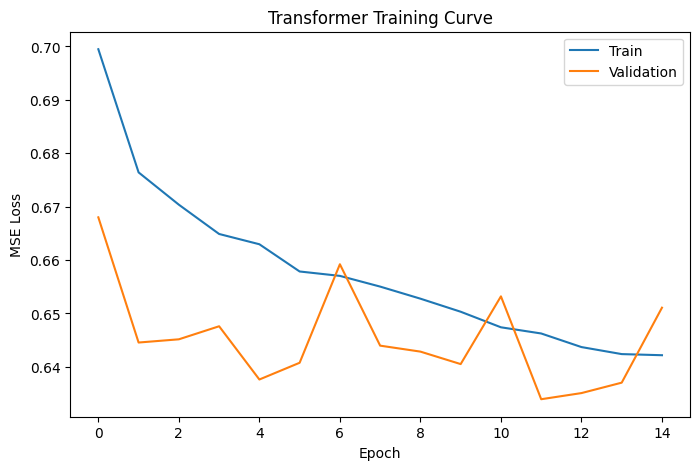

In [21]:
# ============================================================
# TRAINING CURVE
# ============================================================
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Train")
plt.plot(val_losses, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Transformer Training Curve")
plt.legend()
plt.show()



In [22]:
# ============================================================
# FINAL TEST EVALUATION (SCALED SPACE)
# ============================================================
test_loss, y_pred_scaled, y_true_scaled = evaluate(model, test_loader, criterion, device)

print("\nFinal Test Loss (scaled MSE):", round(test_loss, 6))


# ============================================================
# CONVERT PREDICTIONS BACK TO ORIGINAL UNITS
# ============================================================
y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
y_true = scaler_y.inverse_transform(y_true_scaled.reshape(-1, 1)).ravel()


Final Test Loss (scaled MSE): 0.637526


In [23]:

# ============================================================
# METRICS IN ORIGINAL UNITS
# ============================================================
mae = mean_absolute_error(y_true, y_pred)
rmse = np.sqrt(mean_squared_error(y_true, y_pred))
medae = median_absolute_error(y_true, y_pred)
r2 = r2_score(y_true, y_pred)
bias = np.mean(y_pred - y_true)
corr = np.corrcoef(y_true, y_pred)[0, 1]

transformer_metrics_df = pd.DataFrame([{
    "split": "test",
    "MAE": mae,
    "RMSE": rmse,
    "MedAE": medae,
    "R2": r2,
    "Bias": bias,
    "Corr": corr
}])

print("\n=== TRANSFORMER TEST METRICS ===")
print(transformer_metrics_df.to_string(index=False))


=== TRANSFORMER TEST METRICS ===
split      MAE     RMSE  MedAE       R2      Bias     Corr
 test 0.143432 0.265859 0.0715 0.345347 -0.002777 0.589217


In [24]:
# ============================================================
# PER-EPISODE METRICS ON TEST SET
# ============================================================
transformer_test_results = pd.DataFrame({
    "episode_id": meta_test["episode_id"],
    "unique_id": meta_test["unique_id"],
    "recording_id": meta_test["recording_id"],
    "target_frame": meta_test["target_frame"],
    "y_true": y_true,
    "y_pred": y_pred
})

episode_metrics_test = (
    transformer_test_results.groupby("episode_id")
    .apply(lambda g: pd.Series({
        "mae": np.mean(np.abs(g["y_true"] - g["y_pred"])),
        "rmse": np.sqrt(np.mean((g["y_true"] - g["y_pred"]) ** 2)),
        "bias": np.mean(g["y_pred"] - g["y_true"]),
        "n_samples": len(g)
    }))
    .reset_index()
)

print("\n=== TRANSFORMER TEST PER-EPISODE METRICS SUMMARY ===")
print(episode_metrics_test[["mae", "rmse", "bias", "n_samples"]].describe().to_string())

transformer_test_results["error"] = (
    transformer_test_results["y_pred"] - transformer_test_results["y_true"]
)
transformer_test_results["abs_error"] = transformer_test_results["error"].abs()
transformer_test_results["Model"] = "Plain Transformer"


=== TRANSFORMER TEST PER-EPISODE METRICS SUMMARY ===
               mae         rmse         bias    n_samples
count  7471.000000  7471.000000  7471.000000  7471.000000
mean      0.137462     0.170705     0.001989   291.982198
std       0.151563     0.190365     0.161363   146.399357
min       0.010428     0.014390    -1.512941   100.000000
25%       0.047683     0.057562    -0.064112   222.000000
50%       0.085802     0.104638    -0.019108   271.000000
75%       0.165424     0.206454     0.029602   333.000000
max       1.941786     1.966967     1.941786  2082.000000


## Regime-Based Evaluation

Transformer regime-level results are computed on the valid sequence-target rows produced after sequence construction, history filtering, and stride sampling. Therefore, regime counts differ from the full frame-level IDM counts and should be interpreted as sequence-target evaluation counts.

In [25]:
# ============================================================
# REGIME-BASED TEST EVALUATION
# ============================================================
transformer_test_results["regime"] = np.where(
    transformer_test_results["y_true"] < BRAKE_THRESHOLD, "braking",
    np.where(transformer_test_results["y_true"] > ACCEL_THRESHOLD, "accelerating", "steady")
)

regime_metrics = (
    transformer_test_results.groupby("regime")
    .apply(lambda g: pd.Series({
        "MAE": np.mean(np.abs(g["y_true"] - g["y_pred"])),
        "RMSE": np.sqrt(np.mean((g["y_true"] - g["y_pred"]) ** 2)),
        "Bias": np.mean(g["y_pred"] - g["y_true"]),
        "Count": len(g)
    }))
    .reset_index()
)

regime_order = ["accelerating", "braking", "steady"]
regime_metrics["regime"] = pd.Categorical(
    regime_metrics["regime"],
    categories=regime_order,
    ordered=True
)

regime_metrics = regime_metrics.sort_values("regime").reset_index(drop=True)

print("\n=== TRANSFORMER TEST METRICS BY REGIME ===")
print(regime_metrics.to_string(index=False))


=== TRANSFORMER TEST METRICS BY REGIME ===
      regime      MAE     RMSE      Bias     Count
accelerating 0.189335 0.298052 -0.180472  623803.0
     braking 0.423877 0.579914  0.412945  264219.0
      steady 0.064001 0.087536 -0.002001 1293377.0


In [26]:
# ============================================================
# TRAIN / VAL / TEST METRICS IN ORIGINAL UNITS
# ============================================================
def get_predictions_in_original_units(model, loader, scaler_y, criterion, device):
    loss, pred_scaled, true_scaled = evaluate(model, loader, criterion, device)

    pred = scaler_y.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()
    true = scaler_y.inverse_transform(true_scaled.reshape(-1, 1)).ravel()

    metrics = {
        "MAE": mean_absolute_error(true, pred),
        "RMSE": np.sqrt(mean_squared_error(true, pred)),
        "MedAE": median_absolute_error(true, pred),
        "R2": r2_score(true, pred),
        "Bias": np.mean(pred - true),
        "Corr": np.corrcoef(true, pred)[0, 1]
    }

    return loss, pred, true, metrics

train_loss, y_pred_train, y_true_train, metrics_train = get_predictions_in_original_units(
    model, train_loader, scaler_y, criterion, device
)

val_loss, y_pred_val, y_true_val, metrics_val = get_predictions_in_original_units(
    model, val_loader, scaler_y, criterion, device
)

test_loss, y_pred_test, y_true_test, metrics_test = get_predictions_in_original_units(
    model, test_loader, scaler_y, criterion, device
)

transformer_split_metrics_df = pd.DataFrame([
    {"split": "train", **metrics_train},
    {"split": "val", **metrics_val},
    {"split": "test", **metrics_test}
])

print("\n=== TRANSFORMER METRICS BY SPLIT ===")
print(transformer_split_metrics_df.to_string(index=False))


=== TRANSFORMER METRICS BY SPLIT ===
split      MAE     RMSE    MedAE       R2      Bias     Corr
train 0.143083 0.264435 0.072371 0.369281 -0.000876 0.608609
  val 0.144060 0.265108 0.073657 0.349270 -0.001203 0.593334
 test 0.143432 0.265859 0.071500 0.345347 -0.002777 0.589217


## Final Transformer Summary

The table below reports the final Transformer performance on the held-out test split under the current evaluation setup.

In [27]:
# ============================================================
# FINAL TRANSFORMER SUMMARY TABLE
# ============================================================

transformer_summary_df = pd.DataFrame([
    {
        "Model": "Transformer",
        **metrics_test
    }
])

print("\n=== FINAL TRANSFORMER SUMMARY ===")
print(transformer_summary_df.to_string(index=False))


=== FINAL TRANSFORMER SUMMARY ===
      Model      MAE     RMSE  MedAE       R2      Bias     Corr
Transformer 0.143432 0.265859 0.0715 0.345347 -0.002777 0.589217


In [28]:
# ============================================================
# SAVE FINAL TRANSFORMER OUTPUTS
# ============================================================

# Summary metrics
transformer_summary_df.to_csv(
    RUN_DIR / "transformer_final_summary.csv",
    index=False
)

# Split metrics
transformer_split_metrics_df.to_csv(
    RUN_DIR / "transformer_split_metrics.csv",
    index=False
)

# Regime metrics
regime_metrics.to_csv(
    RUN_DIR / f"transformer_regime_metrics_{THRESHOLD_TAG}.csv",
    index=False
)

# Episode metrics
episode_metrics_test.to_csv(
    RUN_DIR / "transformer_episode_metrics.csv",
    index=False
)

# Test predictions
# Standard filename used by the secondary evaluation notebook
transformer_test_results.to_csv(
    RUN_DIR / "transformer_test_predictions.csv",
    index=False
)

# Extra filename with sequence information, useful for avoiding confusion
transformer_test_results.to_csv(
    RUN_DIR / f"transformer_test_predictions_{SEQUENCE_TAG}.csv",
    index=False
)

# Config
with open(RUN_DIR / "transformer_baseline_config.json", "w") as f:
    json.dump({
        "EXPERIMENT_NAME": EXPERIMENT_NAME,
        "SEQUENCE_TAG": SEQUENCE_TAG,
        "BRAKE_THRESHOLD": BRAKE_THRESHOLD,
        "ACCEL_THRESHOLD": ACCEL_THRESHOLD,
        "HISTORY": HISTORY,
        "HORIZON": HORIZON,
        "STRIDE": STRIDE,
        "BATCH_SIZE": BATCH_SIZE,
        "NUM_EPOCHS": NUM_EPOCHS,
        "LR": LR,
        "feature_cols": feature_cols,
        "target_col": target_col,
        "model_config": model_config,
        "best_epoch": best_epoch,
        "best_val_loss": best_val_loss,
        "DATA_DIR": str(DATA_DIR),
        "RUN_DIR": str(RUN_DIR)
    }, f, indent=2)

print("Saved Transformer baseline outputs to:")
print(RUN_DIR)

print("\nSaved prediction files:")
print(RUN_DIR / "transformer_test_predictions.csv")
print(RUN_DIR / f"transformer_test_predictions_{SEQUENCE_TAG}.csv")

Saved Transformer baseline outputs to:
C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\transformer_baseline_runs\transformer_baseline_H25_Hz1_S1_brake0p2_accel0p2

Saved prediction files:
C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\transformer_baseline_runs\transformer_baseline_H25_Hz1_S1_brake0p2_accel0p2\transformer_test_predictions.csv
C:\Users\ANARAMO\Documents\Tese\Tese\Tese\HybridMobility\processed_data_final\transformer_baseline_runs\transformer_baseline_H25_Hz1_S1_brake0p2_accel0p2\transformer_test_predictions_H25_Hz1_S1.csv


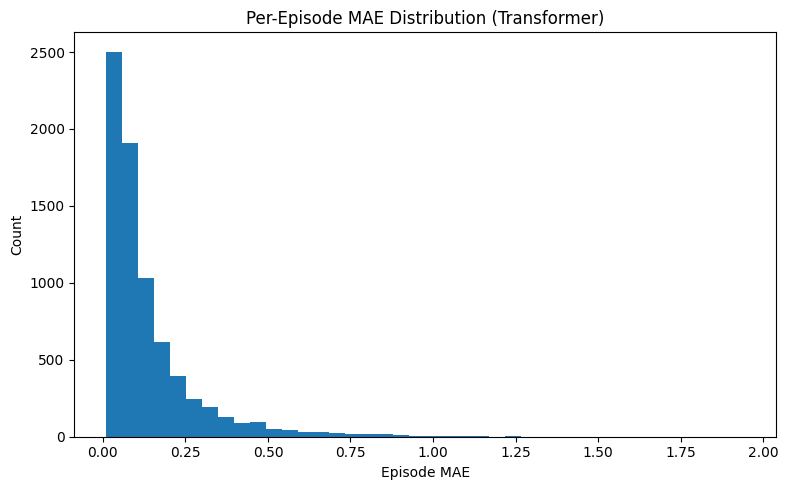

In [29]:
# ============================================================
# VISUAL 1: PER-EPISODE MAE DISTRIBUTION
# ============================================================

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(episode_metrics_test["mae"], bins=40)
ax.set_title("Per-Episode MAE Distribution (Transformer)")
ax.set_xlabel("Episode MAE")
ax.set_ylabel("Count")
plt.tight_layout()
plt.show()

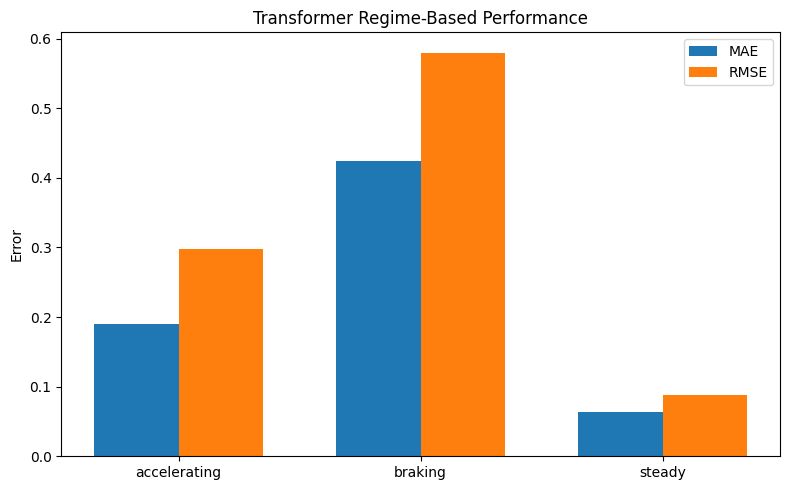

In [30]:
# ============================================================
# VISUAL 2: REGIME-BASED TRANSFORMER PERFORMANCE
# ============================================================

fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(regime_metrics))
width = 0.35

ax.bar(x - width/2, regime_metrics["MAE"], width, label="MAE")
ax.bar(x + width/2, regime_metrics["RMSE"], width, label="RMSE")

ax.set_xticks(x)
ax.set_xticklabels(regime_metrics["regime"])
ax.set_title("Transformer Regime-Based Performance")
ax.set_ylabel("Error")
ax.legend()
plt.tight_layout()
plt.show()

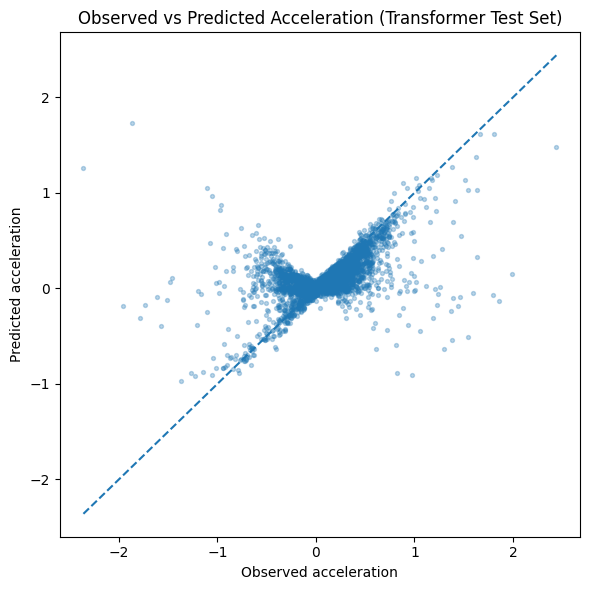

In [31]:
# ============================================================
# VISUAL 3: OBSERVED VS PREDICTED ACCELERATION (TEST SET)
# ============================================================

plot_df = transformer_test_results.sample(
    n=min(5000, len(transformer_test_results)),
    random_state=42
)

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(plot_df["y_true"], plot_df["y_pred"], alpha=0.3, s=8)

min_v = min(plot_df["y_true"].min(), plot_df["y_pred"].min())
max_v = max(plot_df["y_true"].max(), plot_df["y_pred"].max())
ax.plot([min_v, max_v], [min_v, max_v], linestyle="--")

ax.set_title("Observed vs Predicted Acceleration (Transformer Test Set)")
ax.set_xlabel("Observed acceleration")
ax.set_ylabel("Predicted acceleration")
plt.tight_layout()
plt.show()